<a href="https://colab.research.google.com/github/simgealtin/GROUP53_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/simgealtin/GROUP53_CENG313.git
import sys
sys.path.append('/content/GROUP53_CENG313')

Cloning into 'GROUP53_CENG313'...
remote: Enumerating objects: 21, done.
remote: Counting objects: 100% (21/21), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 21 (delta 3), reused 17 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (21/21), 4.68 KiB | 2.34 MiB/s, done.
Resolving deltas: 100% (3/3), done.


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from src.data import load_data

DATA_DIR = '/content/drive/MyDrive/CENG313_data/'
train, test, sample_sub = load_data(DATA_DIR)

print(train.shape, test.shape)
train.head()

(230130, 6) (98550, 5)


,id,date,country,store,product,num_sold
0,0,2010-01-01,Canada,Discount Stickers,Holographic Goose,NaN
1,1,2010-01-01,Canada,Discount Stickers,Kaggle,973.0
2,2,2010-01-01,Canada,Discount Stickers,Kaggle Tiers,906.0
3,3,2010-01-01,Canada,Discount Stickers,Kerneler,423.0
4,4,2010-01-01,Canada,Discount Stickers,Kerneler Dark Mode,491.0


The train dataset consists of 230130 rows and 6 columns, while the test dataset contains 98550 rows and 5 columns. The num_sold column is missing from the test dataset because it is the target variable to be predicted.

In [5]:
train.info() # data types and general information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 230130 entries, 0 to 230129
Data columns (total 6 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   id        230130 non-null  int64         
 1   date      230130 non-null  datetime64[ns]
 2   country   230130 non-null  object        
 3   store     230130 non-null  object        
 4   product   230130 non-null  object        
 5   num_sold  221259 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(3)
memory usage: 10.5+ MB


The train data consists of 230130 rows but we only see 221259 rows for num_sold column. That makes 8871 missing values. I will analyze whether these missing values are random or concentrated in specific countries, stores, or products.

In [7]:
train.isnull().sum() # missing values

,0
id,0
date,0
country,0
store,0
product,0
num_sold,8871


The missing values are only in the num_sold column which is the target variable for the test dataset.


In [8]:
# date interval
print(train['date'].min(), train['date'].max())
print(test['date'].min(), test['date'].max())

2010-01-01 00:00:00 2016-12-31 00:00:00
2017-01-01 00:00:00 2019-12-31 00:00:00


The test dataset starts from the end date of the train dataset and covers a period of 3 years. Since this is a forecasting problem I will use a timebased split for validation.

In [9]:
# object columns
for col in ['country', 'store', 'product']:
  print(col, train[col].unique())

country ['Canada' 'Finland' 'Italy' 'Kenya' 'Norway' 'Singapore']
store ['Discount Stickers' 'Stickers for Less' 'Premium Sticker Mart']
product ['Holographic Goose' 'Kaggle' 'Kaggle Tiers' 'Kerneler'
 'Kerneler Dark Mode']


The data is consisting of 6 countries, 3 stores and 5 products which makes 90 different combination of these three categories. Daily sales data for every combination exists.

In [10]:
# num_sold statistics
train['num_sold'].describe()

,num_sold
count,221259.000000
mean,752.527382
std,690.165445
min,5.000000
25%,219.000000
50%,605.000000
75%,1114.000000
max,5939.000000


The mean of num_sold is 752, while the median is 605. Since the mean is greater than the median, this indicates that the distribution is right-skewed. The minimum value is 5, so there is no risk of division by zero. However, the MAPE(Mean Absolute Percentage Error) metric will be highly sensitive to errors in observations with low sales values.

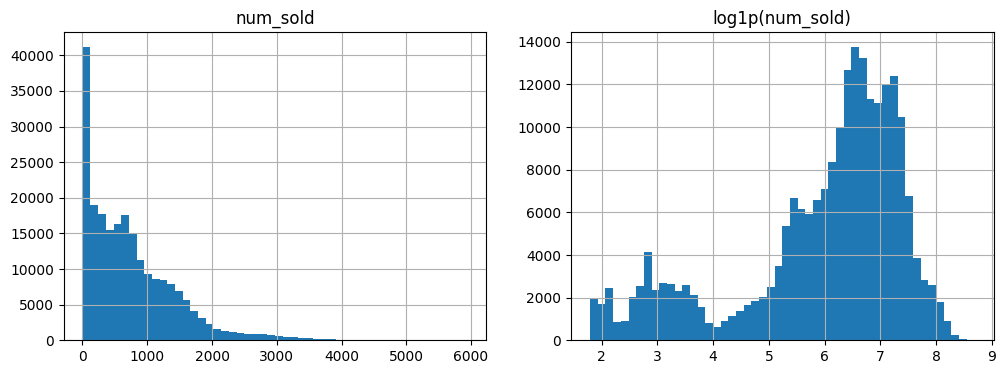

In [11]:
# distribution of num_sold
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train['num_sold'].hist(bins=50, ax=axes[0])
axes[0].set_title('num_sold')
np.log1p(train['num_sold']).hist(bins=50, ax=axes[1])
axes[1].set_title('log1p(num_sold)')
plt.show()


The raw num_sold values follow a right-skewed distribution. Applying the log1p transformation makes the distribution considerably more balanced and reduces the influence of outliers. A second, smaller peak appears at lower values in the log-transformed distribution, suggesting that the data may contain groups with different sales scales (possibly across countries). I will investigate this further by examining sales distributions by country.
I will also experiment with applying the log1p transformation to the target variable during model training.

In [12]:
# where did the mising values gather?
train[train['num_sold'].isnull()].groupby(['country', 'product']).size()

country  product           
Canada   Holographic Goose     4245
         Kerneler                 1
Kenya    Holographic Goose     4561
         Kerneler                63
         Kerneler Dark Mode       1
dtype: int64

99% of the missing values are gathered in two sets: Canada-Holographic Goose and Kenya-Holographic Goose. Missing values are not random, they are specific to certain sets. Therefore, imputing missing values using the overall dataset mean would be inappropriate. I will examine which dates have the highest concentration of missing values and then decide whether to remove them or apply time-series-based imputation.

In [13]:
#Average sales by country (Could this explain the second peak in the distribution?)
train.groupby('country')['num_sold'].agg(['mean', 'median', 'count'])

,mean,median,count
country,,,
Canada,840.045003,731.0,34109
Finland,748.243306,665.0,38355
Italy,542.241403,480.0,38355
Kenya,20.431100,18.0,33730
Norway,1422.560422,1261.0,38355
Singapore,863.052379,772.0,38355


Sales amounts vary significantly across countries. Norway has the highest average sales at 1422, while Kenya has a considerably lower average of just 20. The second peak in the log-transformed distribution is caused by Kenya. Since MAPE measures relative error, even small deviations in Kenya can disproportionately affect the overall score. I will make sure to include country information in the models and perform a separate error analysis for Kenya.